# Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scypy as sp
import duckdb
from sklearn import linear_model, metrics, model_selection, feature_selection


In [2]:
# Import data
from flamesafe import config

con = duckdb.connect(str(config.data_dir() / "gold" / "flamesafe.duckdb"), read_only=True)

gas = con.sql("""
    SELECT g.*, i.acronym, i.tier, i.hardware_family, i.environments
    FROM gas_flame_tests g
    LEFT JOIN investigations i USING (psi_id)
""").df()      # sigue teniendo 660 filas: una por prueba

In [3]:
pubs = con.sql("""
    SELECT i.psi_id, i.acronym, i.tier, p.doi, p.title
    FROM (SELECT *, unnest(psi_ids) AS psi_id FROM publications) p
    JOIN investigations i USING (psi_id)
""").df()

In [4]:
gas.describe()

,test_day,fuel_dilution_pct,xo2,xo2_final,x_fuel,p_kpa,po2_kpa,m_fuel_mg_s,hc_burnrate_mg_s,m_o2_mg_s,m_n2_mg_s,m_total_mg_s,zst,tad_k,burn_time_s,peak_burner_t_k,source_row,tier
count,660.000000,540.000000,649.000000,366.000000,600.000000,660.000000,649.000000,326.000000,154.000000,266.000000,256.000000,256.000000,587.000000,587.000000,329.000000,285.000000,660.000000,660.0
mean,6.072727,82.314815,0.433134,0.314715,0.309310,131.988682,61.361430,1.259302,1.351668,4.678071,3.338405,5.993433,0.356401,2410.860759,36.996960,482.813561,87.110606,1.0
std,3.499948,29.517030,0.228630,0.083525,0.292838,74.711242,60.879802,0.685794,0.668340,2.139197,3.346393,3.722626,0.213543,327.200406,51.880065,151.765722,52.616962,0.0
min,0.000000,30.000000,0.120000,0.179392,0.000000,43.161204,7.430725,0.000000,0.250000,0.931126,0.000000,0.312674,0.058763,1397.031071,0.000000,273.150000,2.000000,1.0
25%,3.000000,50.000000,0.216404,0.210206,0.098731,101.330000,21.504733,0.800000,0.750000,3.378386,0.554626,2.607378,0.164304,2225.471861,3.000000,350.750000,43.000000,1.0
50%,6.000000,100.000000,0.384642,0.366423,0.204981,102.766412,39.936051,1.032367,1.500000,4.594625,2.549401,5.580742,0.325704,2499.463612,17.000000,442.350000,84.000000,1.0
75%,9.000000,100.000000,0.500000,0.385121,0.300000,129.776638,65.874633,1.600000,1.500000,5.441973,5.933188,8.830240,0.528717,2647.995970,56.000000,589.150000,126.250000,1.0
max,13.000000,100.000000,0.850000,0.397259,1.000000,330.990000,281.341500,3.215000,2.500000,9.799338,20.240225,21.540651,0.783918,2978.371796,304.000000,924.650000,208.000000,1.0


In [5]:
pubs.describe()

,tier
count,351.000000
mean,2.182336
std,0.875590
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,3.000000


# Análisis de variables numéricas

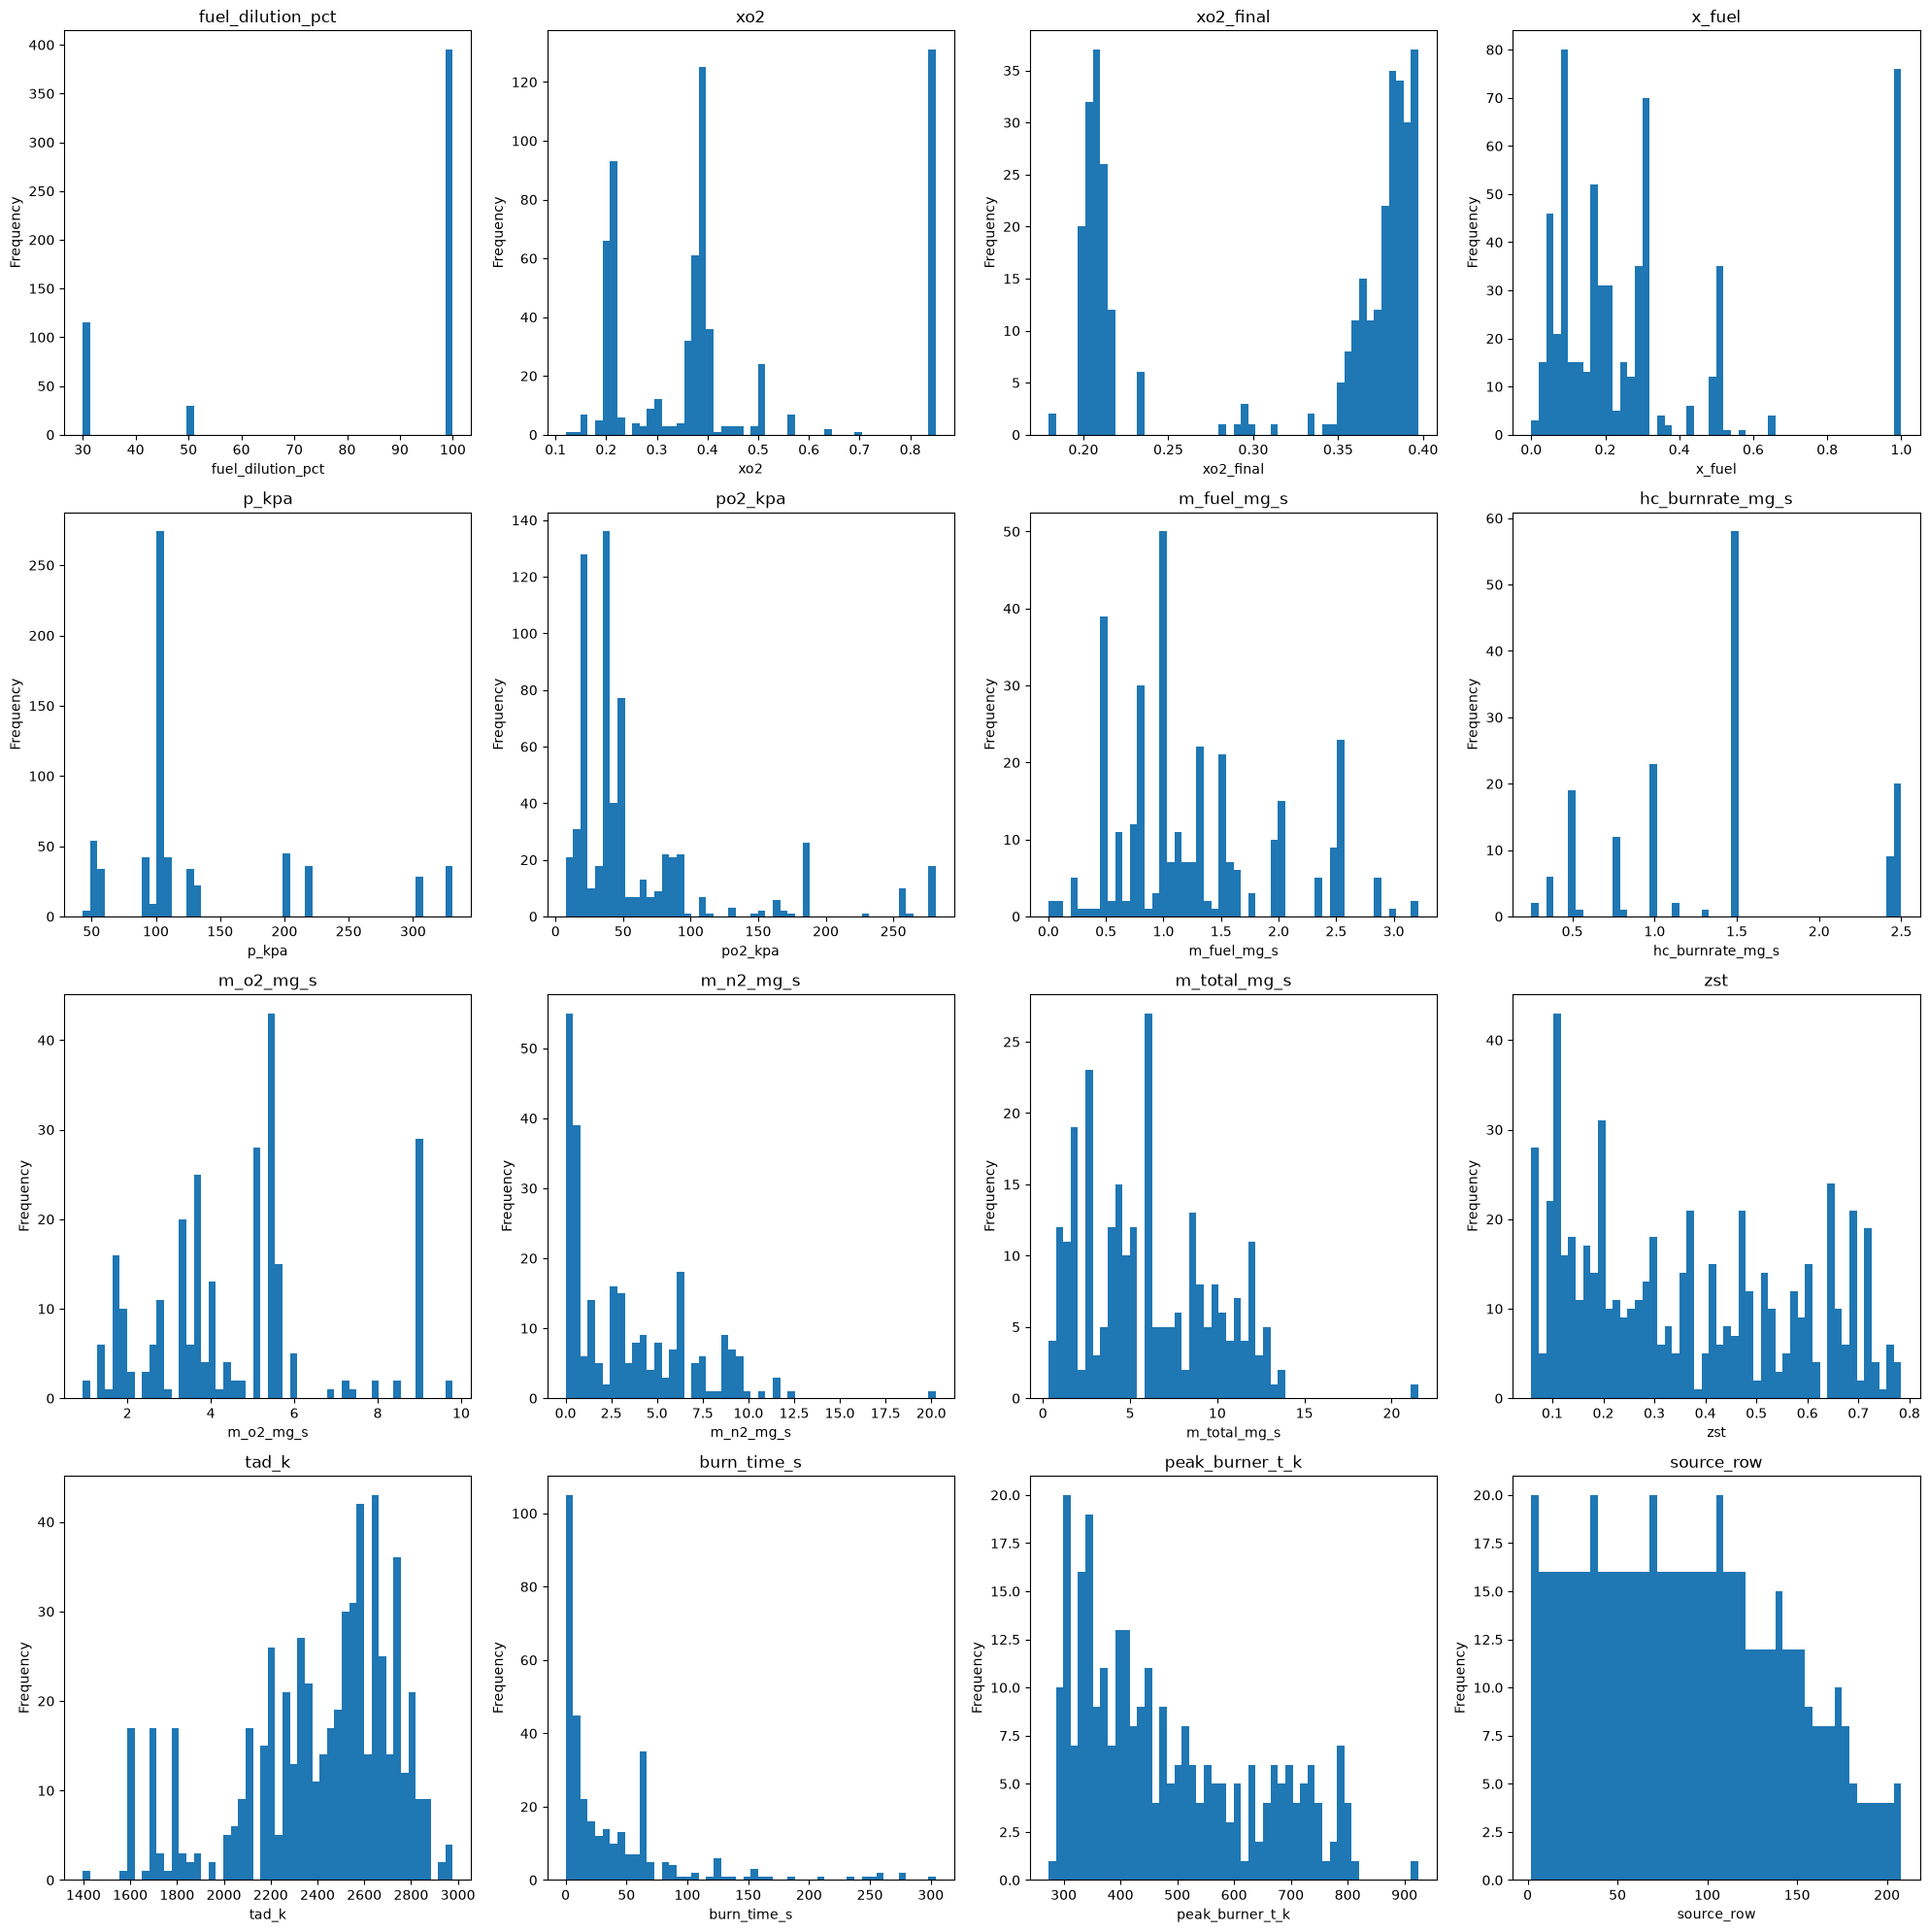

In [46]:
numericas_gas = gas.select_dtypes(include=['int64', 'float64'])
numericas_gas = numericas_gas.drop(columns=['tier', 'test_day'])

fig, axes = plt.subplots(4, 4, figsize=(20, 20))
for i, col in enumerate(numericas_gas.columns[:16]):  # Limitar a las primeras 16 columnas
    row = (i // 4)
    col_idx = i % 4
    axes[row, col_idx].hist(numericas_gas[col], bins=50)
    axes[row, col_idx].set_title(col)
    axes[row, col_idx].set_xlabel(col)
    axes[row, col_idx].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

<Axes: >

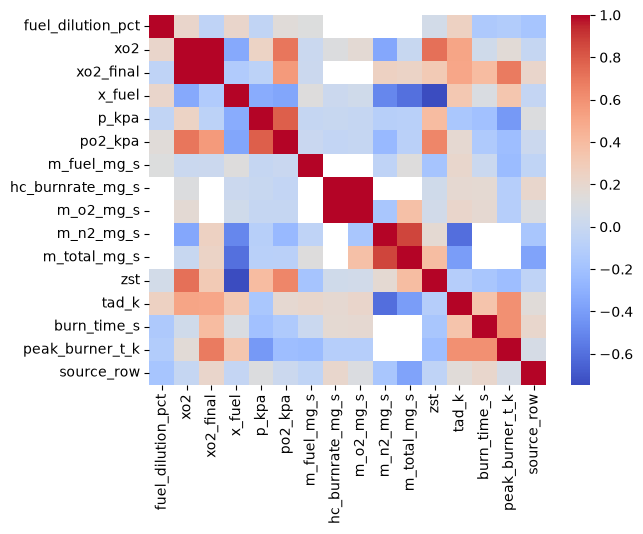

In [45]:
sns.heatmap(numericas_gas.corr(), cmap='coolwarm')

CV: 1.4022791160390704


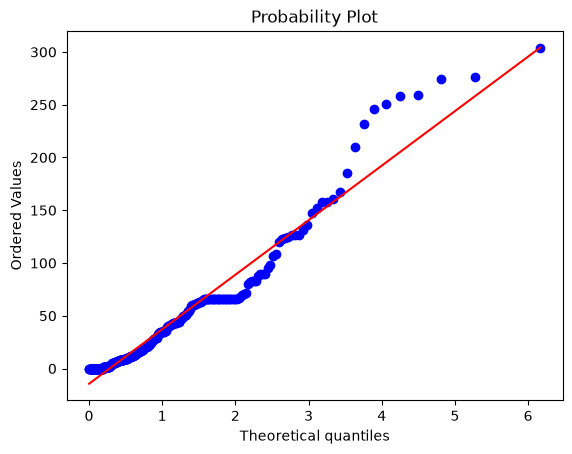

C:\Users\ugams\AppData\Local\Temp\ipykernel_30200\2042386612.py:19: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  AD = stats.anderson(x, dist="expon")


p-valor bootstrap: 0.0
KS: KstestResult(statistic=np.float64(0.21649386782823976), pvalue=np.float64(5.127521071139137e-14), statistic_location=np.float64(1.0), statistic_sign=np.int8(1))
AD: AndersonResult(statistic=np.float64(inf), critical_values=array([0.914, 1.06 , 1.319, 1.588, 1.955]), significance_level=array([15. , 10. ,  5. ,  2.5,  1. ]), fit_result=  params: FitParams(loc=np.float64(0.0), scale=np.float64(36.99696048632219))
 success: True
 message: '`anderson` successfully fit the distribution to the data.')


In [54]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

x = np.array(gas['burn_time_s'].dropna())  # Asegúrate de reemplazar 'burn_time' con el nombre correcto de la columna

# Estimación de lambda
lam = 1 / x.mean()
print("CV:", x.std(ddof=1) / x.mean())   # debería ser ≈ 1

# Q-Q plot
stats.probplot(x, dist="expon", plot=plt)
plt.show()

# Kolmogorov-Smirnov (cuidado con el parámetro estimado)
KS = stats.kstest(x, "expon", args=(0, 1/lam))

# Anderson-Darling para exponencial
AD = stats.anderson(x, dist="expon")

# Bootstrap paramétrico para p-valor correcto
def ks_stat(sample):
    l = 1 / sample.mean()
    return stats.kstest(sample, "expon", args=(0, 1/l)).statistic

obs = ks_stat(x)
sim = [ks_stat(np.random.exponential(1/lam, len(x))) for _ in range(5000)]
print("p-valor bootstrap:", np.mean(np.array(sim) >= obs))
print("KS:", KS)
print("AD:", AD)

In [42]:
categoricas_gas = gas.select_dtypes(include=['object', 'category'])
categoricas_gas 

C:\Users\ugams\AppData\Local\Temp\ipykernel_30200\4129444628.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas_gas = gas.select_dtypes(include=['object', 'category'])


,psi_id,campaign,test_id,flame_type,fuel,p_source,ignition_outcome,outcome_source,extinction_mode,qualifier,source_file,acronym,hardware_family,environments
0,PSI-159,CFI-G,21088A1,normal,ethane,approx p (bar),yes,experimental_table,self_extinguished,NaN,PSI-159_Experimental table_CFI-G_Normal Flames...,ACME CFI-G,CIR-ACME,"nave, estacion, base_lunar, rover, marte"
1,PSI-159,CFI-G,21088B1,normal,ethane,approx p (bar),yes,experimental_table,self_extinguished,NaN,PSI-159_Experimental table_CFI-G_Normal Flames...,ACME CFI-G,CIR-ACME,"nave, estacion, base_lunar, rover, marte"
2,PSI-159,CFI-G,21088C1,normal,ethane,approx p (bar),yes,experimental_table,self_extinguished,NaN,PSI-159_Experimental table_CFI-G_Normal Flames...,ACME CFI-G,CIR-ACME,"nave, estacion, base_lunar, rover, marte"
3,PSI-159,CFI-G,21088D1,normal,ethane,approx p (bar),yes,experimental_table,flow_terminated,NaN,PSI-159_Experimental table_CFI-G_Normal Flames...,ACME CFI-G,CIR-ACME,"nave, estacion, base_lunar, rover, marte"
4,PSI-159,CFI-G,21088F1,normal,ethane,approx p (bar),yes,experimental_table,flow_terminated,NaN,PSI-159_Experimental table_CFI-G_Normal Flames...,ACME CFI-G,CIR-ACME,"nave, estacion, base_lunar, rover, marte"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
655,PSI-10,Flame Design,22035J3,inverse,ethylene,pmean (atm),yes,eventdata,NaN,NaN,PSI-10_Experimental table_Flame Design_Inverse...,ACME/Flame Design,CIR-ACME,"nave, estacion, base_lunar, rover, marte"
656,PSI-10,Flame Design,22035J4,inverse,ethylene,pmean (atm),yes,eventdata,NaN,NaN,PSI-10_Experimental table_Flame Design_Inverse...,ACME/Flame Design,CIR-ACME,"nave, estacion, base_lunar, rover, marte"
657,PSI-10,Flame Design,22035J5,inverse,ethylene,pmean (atm),yes,eventdata,NaN,NaN,PSI-10_Experimental table_Flame Design_Inverse...,ACME/Flame Design,CIR-ACME,"nave, estacion, base_lunar, rover, marte"
658,PSI-10,Flame Design,22035J6,inverse,ethylene,pmean (atm),yes,eventdata,NaN,NaN,PSI-10_Experimental table_Flame Design_Inverse...,ACME/Flame Design,CIR-ACME,"nave, estacion, base_lunar, rover, marte"


In [47]:
categoricas_gas.describe()

,psi_id,campaign,test_id,flame_type,fuel,p_source,ignition_outcome,outcome_source,extinction_mode,qualifier,source_file,acronym,hardware_family,environments
count,660,660,660,660,660,660,658,660,272,71,660,660,660,660
unique,2,2,660,2,4,3,3,3,2,3,4,2,1,1
top,PSI-159,CFI-G,21088A1,normal,ethylene,approx p (bar),yes,experimental_table,self_extinguished,RAMP,PSI-10_Experimental table_Flame Design_Normal ...,ACME CFI-G,CIR-ACME,"nave, estacion, base_lunar, rover, marte"
freq,333,333,1,386,307,333,586,333,183,66,207,333,660,660


In [55]:
gas["extinction_mode"].value_counts()

extinction_mode
self_extinguished    183
flow_terminated       89
Name: count, dtype: int64

In [57]:
print(gas.groupby("extinction_mode")["burn_time_s"].describe())
print(gas[gas.extinction_mode == "flow_terminated"]["burn_time_s"].round(0).value_counts().head(10))

                   count       mean        std   min   25%   50%   75%    max
extinction_mode                                                              
flow_terminated     89.0  70.494382  51.476412  12.0  36.0  66.0  67.0  276.0
self_extinguished  183.0  32.229508  50.687410   0.5   6.0  13.0  39.5  304.0
burn_time_s
66.0     26
43.0      4
127.0     3
35.0      3
61.0      2
63.0      2
29.0      2
36.0      2
26.0      2
12.0      2
Name: count, dtype: int64


array([<Axes: title={'center': 'flow_terminated'}>,
       <Axes: title={'center': 'self_extinguished'}>], dtype=object)

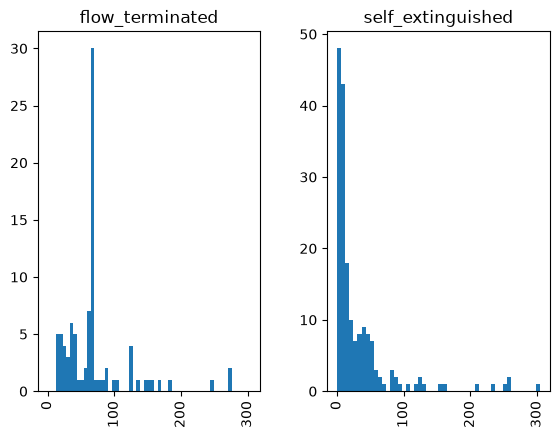

In [59]:
gas.hist("burn_time_s", by="extinction_mode", bins=50, sharex=True)

CV: 0.730220061623885


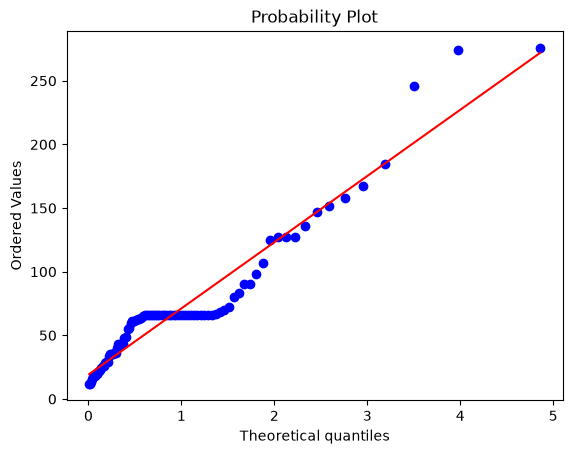

C:\Users\ugams\AppData\Local\Temp\ipykernel_30200\1055829117.py:19: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  AD = stats.anderson(x, dist="expon")


p-valor bootstrap: 0.0
KS: KstestResult(statistic=np.float64(0.21351791868243963), pvalue=np.float64(0.0004858840447158158), statistic_location=np.float64(60.0), statistic_sign=np.int8(-1))
AD: AndersonResult(statistic=np.float64(7.704105267411407), critical_values=array([0.91 , 1.055, 1.312, 1.58 , 1.946]), significance_level=array([15. , 10. ,  5. ,  2.5,  1. ]), fit_result=  params: FitParams(loc=np.float64(0.0), scale=np.float64(70.49438202247191))
 success: True
 message: '`anderson` successfully fit the distribution to the data.')


In [63]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

x = np.array(gas['burn_time_s'][gas['extinction_mode'] == "flow_terminated"].dropna())  # Asegúrate de reemplazar 'burn_time' con el nombre correcto de la columna

# Estimación de lambda
lam = 1 / x.mean()
print("CV:", x.std(ddof=1) / x.mean())   # debería ser ≈ 1

# Q-Q plot
stats.probplot(x, dist="expon", plot=plt)
plt.show()

# Kolmogorov-Smirnov (cuidado con el parámetro estimado)
KS = stats.kstest(x, "expon", args=(0, 1/lam))

# Anderson-Darling para exponencial
AD = stats.anderson(x, dist="expon")

# Bootstrap paramétrico para p-valor correcto
def ks_stat(sample):
    l = 1 / sample.mean()
    return stats.kstest(sample, "expon", args=(0, 1/l)).statistic

obs = ks_stat(x)
sim = [ks_stat(np.random.exponential(1/lam, len(x))) for _ in range(5000)]
print("p-valor bootstrap:", np.mean(np.array(sim) >= obs))
print("KS:", KS)
print("AD:", AD)

extinction_mode  flow_terminated  self_extinguished
campaign                                           
CFI-G                         89                183
campaign
CFI-G    30
Name: count, dtype: int64
hardware_family
CIR-ACME    30
Name: count, dtype: int64
qualifier
NaN       589
RAMP       66
RAMPED      3
LOW O2      2
Name: count, dtype: int64
extinction_mode  flow_terminated  self_extinguished  NaN
ignited                                                 
False                          1                  0   63
True                          88                175  323
<NA>                           0                  8    2


<Axes: title={'center': 'burn_time_s'}, xlabel='campaign'>

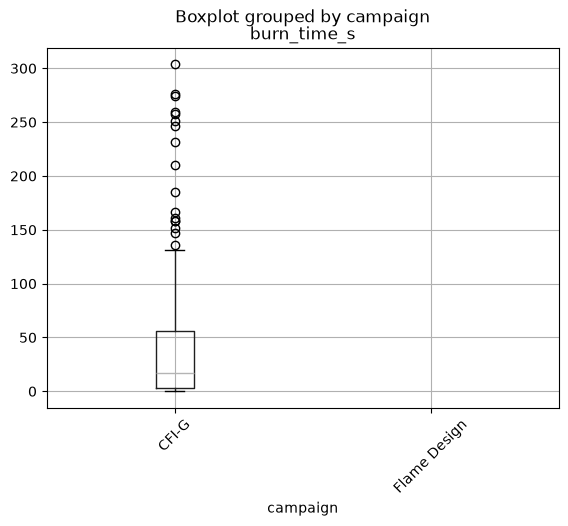

In [67]:
# 1. Los picos por campaña / hardware
print(pd.crosstab(gas["campaign"], gas["extinction_mode"]))
print(gas[gas.burn_time_s.between(64, 68)]["campaign"].value_counts())
print(gas[gas.burn_time_s.between(64, 68)]["hardware_family"].value_counts())

# 2. Qué dice qualifier y la ignición
print(gas["qualifier"].value_counts(dropna=False).head(15))
print(pd.crosstab(gas["ignited"], gas["extinction_mode"], dropna=False))

# 3. Burn time por campaña
gas.boxplot(column="burn_time_s", by="campaign", rot=45)

In [68]:
gas["campaign"].value_counts()

campaign
CFI-G           333
Flame Design    327
Name: count, dtype: int64

In [69]:
print(gas["burn_time_s"].notna().sum())
print(gas.groupby(gas.extinction_mode.isna())["burn_time_s"].apply(lambda s: s.notna().mean()))

329
extinction_mode
False    1.000000
True     0.146907
Name: burn_time_s, dtype: float64


In [70]:
print(pd.crosstab(gas["qualifier"].fillna("none"), gas["extinction_mode"].fillna("sin_modo")))
print(gas.groupby(gas.qualifier.fillna("none"))["burn_time_s"].describe())

extinction_mode  flow_terminated  self_extinguished  sin_modo
qualifier                                                    
LOW O2                         0                  0         2
RAMP                           0                  0        66
RAMPED                         0                  0         3
none                          89                183       317
           count      mean        std  min  25%   50%   75%    max
qualifier                                                         
LOW O2       0.0       NaN        NaN  NaN  NaN   NaN   NaN    NaN
RAMP         0.0       NaN        NaN  NaN  NaN   NaN   NaN    NaN
RAMPED       0.0       NaN        NaN  NaN  NaN   NaN   NaN    NaN
none       329.0  36.99696  51.880065  0.0  3.0  17.0  56.0  304.0


In [75]:
d = gas[gas.extinction_mode.notna()].copy()
d["cut"] = (d.extinction_mode == "flow_terminated").astype(int)
print(d.groupby("cut")[["xo2", "p_kpa", "m_fuel_mg_s", "po2_kpa"]].describe().T)

cut                         0           1
xo2         count  183.000000   89.000000
            mean     0.474176    0.485906
            std      0.252628    0.249425
            min      0.135000    0.150000
            25%      0.216662    0.300000
            50%      0.391980    0.385474
            75%      0.850000    0.850000
            max      0.850000    0.850000
p_kpa       count  183.000000   89.000000
            mean   173.041588  114.224220
            std     93.253473   74.383252
            min     49.538170   49.538170
            25%    101.330000   55.165000
            50%    110.330000  101.330000
            75%    220.660000  110.330000
            max    330.990000  330.990000
m_fuel_mg_s count  102.000000   31.000000
            mean     1.303676    0.940000
            std      0.662498    0.490680
            min      0.125000    0.500000
            25%      0.887500    0.625000
            50%      1.200000    0.800000
            75%      1.600000    1

In [76]:
con_t = gas["burn_time_s"].notna()

# 1. Las 57 con tiempo pero sin modo
sin_modo = gas[con_t & gas.extinction_mode.isna()]
print(sin_modo["burn_time_s"].describe())
print(sin_modo["ignited"].value_counts(dropna=False))
print(sin_modo["ignition_outcome"].value_counts(dropna=False))

# 2. Las 260 sin tiempo y sin qualifier
resto = gas[~con_t & gas.qualifier.isna()]
print(resto["ignited"].value_counts(dropna=False))
print(resto["ignition_outcome"].value_counts(dropna=False).head(10))
print(resto[["xo2_final", "peak_burner_t_k", "tfp"]].notna().mean())

count    57.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: burn_time_s, dtype: float64
ignited
False    57
Name: count, dtype: Int64
ignition_outcome
no    57
Name: count, dtype: int64
ignited
True     253
False      6
<NA>       1
Name: count, dtype: Int64
ignition_outcome
yes    253
no       6
NaN      1
Name: count, dtype: int64
xo2_final          0.503846
peak_burner_t_k    0.000000
tfp                0.015385
dtype: float64


In [78]:
import pandas as pd
from scipy.stats import chi2_contingency

cmp = gas[gas.ignited == True].copy()
cmp["tiene_t"] = cmp["burn_time_s"].notna()

for col in ["fuel", "flame_type", "source_file", "test_day"]:
    tab = pd.crosstab(cmp[col], cmp["tiene_t"])
    prop = tab.div(tab.sum(axis=1), axis=0).round(2)   # proporción por fila
    chi2, p, dof, _ = chi2_contingency(tab)
    print(f"\n== {col} == (chi2 p = {p:.4f})")
    print(pd.concat([tab, prop.add_suffix("_prop")], axis=1))


== fuel == (chi2 p = 0.0000)
tiene_t   False  True  False_prop  True_prop
fuel                                        
butane        0   105        0.00       1.00
ethane        0    81        0.00       1.00
ethylene    305     0        1.00       0.00
propane      18    77        0.19       0.81

== flame_type == (chi2 p = 0.0016)
tiene_t     False  True  False_prop  True_prop
flame_type                                    
inverse       118   131        0.47       0.53
normal        205   132        0.61       0.39

== source_file == (chi2 p = 0.0000)
tiene_t                                             False  True  False_prop  \
source_file                                                                   
PSI-10_Experimental table_Flame Design_Inverse ...    118     0         1.0   
PSI-10_Experimental table_Flame Design_Normal F...    205     0         1.0   
PSI-159_Experimental table_CFI-G_Inverse Flames...      0   131         0.0   
PSI-159_Experimental table_CFI-G_Normal Flam